In [9]:
'''
PyTorch 1.0 强化学习 (Packt Publishing)
第2章：马尔可夫决策过程与动态规划 (价值迭代 Value Iteration)
作者：Yuxi (Hayden) Liu
修改说明：升级至 gymnasium 库 (FrozenLake-v1)，适配新版 API，增加详细中文注释、中文输出及图表中文支持
'''

import torch
import gymnasium as gym  # 使用新版 gymnasium 库
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# ==========================================
# 配置 Matplotlib 中文字体支持
# ==========================================
# 自动检测系统可用的中文字体
zh_fonts = [f.name for f in fm.fontManager.ttflist if any(k in f.name for k in ['SimHei', 'Microsoft YaHei', 'PingFang SC', 'Heiti SC', 'WenQuanYi Micro Hei', 'Noto Sans CJK SC'])]
if zh_fonts:
    plt.rcParams['font.sans-serif'] = [zh_fonts[0]]
else:
    plt.rcParams['font.sans-serif'] = ['SimHei']  # 默认尝试黑体
plt.rcParams['axes.unicode_minus'] = False  # 正常显示负号

# 创建 FrozenLake-v1 环境
env = gym.make('FrozenLake-v1')

# 折扣因子 (gamma)：决定智能体对长远奖励的重视程度，0.99 表示极度看重未来
gamma = 0.99

# 收敛阈值：当所有状态的价值更新幅度小于此值时，认为算法已收敛
threshold = 0.0001


def value_iteration(env, gamma, threshold):
    """
    使用价值迭代算法求解环境的最优价值函数
    @param env: Gymnasium 环境
    @param gamma: 折扣因子
    @param threshold: 收敛阈值
    @return: 最优状态价值函数 V*(s)
    """
    n_state = env.observation_space.n
    n_action = env.action_space.n
    
    # 初始化所有状态的价值为 0
    V = torch.zeros(n_state)
    
    iteration_count = 0  # 记录迭代次数
    
    while True:
        iteration_count += 1
        V_temp = torch.empty(n_state)  # 临时存储更新后的价值
        
        # 遍历所有状态，应用贝尔曼最优方程
        for state in range(n_state):
            v_actions = torch.zeros(n_action)  # 存储当前状态下每个动作的期望价值 (Q值)
            
            # 遍历所有可能的动作
            for action in range(n_action):
                # 遍历该动作下所有可能的状态转移 (概率, 新状态, 奖励, 是否终止)
                for trans_prob, new_state, reward, _ in env.unwrapped.P[state][action]:
                    # 贝尔曼方程核心：Q(s,a) = Σ P(s'|s,a) * [R + γ * V(s')]
                    v_actions[action] += trans_prob * (reward + gamma * V[new_state])
            
            # 价值迭代的核心：取最大动作价值作为当前状态的新价值 (V(s) = max Q(s,a))
            V_temp[state] = torch.max(v_actions)
            
        # 计算本次迭代中所有状态价值的最大变化量
        max_delta = torch.max(torch.abs(V - V_temp))
        
        # 更新价值表
        V = V_temp.clone()
        
        # 如果最大变化量小于阈值，说明已经收敛，停止迭代
        if max_delta <= threshold:
            break
            
    print(f"【价值迭代完成】共迭代 {iteration_count} 次达到收敛。")
    return V


def extract_optimal_policy(env, V_optimal, gamma):
    """
    根据最优价值函数提取最优策略 (贪心策略)
    @param env: Gymnasium 环境
    @param V_optimal: 最优价值函数，由 value_iteration 函数计算得到
    @param gamma: 折扣因子
    @return: 最优策略 (每个状态对应的最佳动作索引)
    """
    n_state = env.observation_space.n
    n_action = env.action_space.n
    optimal_policy = torch.zeros(n_state)
    
    for state in range(n_state):
        v_actions = torch.zeros(n_action)
        
        for action in range(n_action):
            for trans_prob, new_state, reward, _ in env.unwrapped.P[state][action]:
                # 计算每个动作的期望价值  Q(s,a) = Σ P(s'|s,a) * [R + γ * V(s')]；V(s′) ：对应代码中的 V_optimal[new_state]，即下一个状态的状态价值。
                v_actions[action] += trans_prob * (reward + gamma * V_optimal[new_state])
                
        # 选择状态中价值最大的动作作为该状态的最优动作
        optimal_policy[state] = torch.argmax(v_actions)
        
    return optimal_policy

这行代码 `v_actions = torch.zeros(n_action)` 在价值迭代中扮演着极其关键的“过渡桥梁”角色。要理解为什么必须存储这个动作价值（Q值），我们需要从**数学定义**和**算法实现**两个层面来剖析：

### 1. 数学层面：V(s) 的计算必须依赖 Q(s,a)
在强化学习中，我们有两个核心的价值函数：
*   **状态价值函数 $V(s)$**：回答“**站在这个格子里**，未来能拿多少分”。
*   **动作价值函数 $Q(s,a)$**：回答“**站在这个格子里，往某个方向走**，未来能拿多少分”。

价值迭代的核心是求解**贝尔曼最优方程**，其数学表达为：
$$V(s) = \max_a Q(s,a)$$
也就是说，一个状态的最高价值，等于在这个状态下执行所有可能动作中，**价值最大的那个动作的 Q 值**。因此，要算出 $V(s)$，我们必须先算出当前状态下每个动作对应的 $Q(s,a)$。

### 2. 代码层面：充当“候选池”与“决策依据”
在代码的 `for state in range(n_state):` 循环中，智能体正站在某一个具体的格子上。此时：
*   `n_action` 代表环境允许的移动方向数（在 FrozenLake 中是 4 个：上下左右）。
*   `v_actions = torch.zeros(n_action)` 创建了一个长度为 4 的一维张量（相当于一个临时的小表格）。

**它的具体工作流程如下：**
1.  **收集候选分数**：内层的 `for action in range(n_action):` 循环会依次评估“向左走”、“向下走”、“向右走”、“向上走”的期望收益，并将算出的 Q 值分别存入 `v_actions[0]` 到 `v_actions[3]` 中。
2.  **贪心决策（取最大值）**：当 4 个动作的 Q 值都算完并存入 `v_actions` 后，代码执行 `V_temp[state] = torch.max(v_actions)`。这就完美对应了数学公式里的 $\max_a$ 操作，挑出最好的动作分数，作为当前格子的最终价值 $V(s)$。
3.  **提取最优策略**：在后续的 `extract_optimal_policy` 函数中，同样是先算出 `v_actions`，然后使用 `torch.argmax(v_actions)` 找出最大值的**索引（Index）**。这个索引（0,1,2,3）就直接告诉了我们最优策略应该往哪个方向走。

### 💡 总结
如果没有 `v_actions` 这个临时容器来存储动作价值，智能体就无法比较“往哪个方向走更好”，也就无法执行 $\max$ 操作来更新状态价值 $V(s)$，更无法最终推导出最优策略。它是连接“环境反馈”与“策略优化”的必经之路。

`env.unwrapped.P[state][action]` 就是环境的 **“底牌”**，也就是马尔可夫决策过程（MDP）中的 **状态转移概率矩阵** 。

在价值迭代这种“白盒”算法中，智能体不需要去环境里瞎撞试错，而是直接通过查看这张表，就能在脑海中**精确推演**出未来每一步的可能结果。

### 📖 具体含义拆解
*   **`env.P`**：代表 Probability（概率），它是一个嵌套字典，记录了环境中所有状态转移的规则。
*   **`[state]`**：当前的状态（在 FrozenLake 中是 0 到 15 的整数，代表 4x4 网格的 16 个格子）。
*   **`[action]`**：执行的动作（0=左，1=下，2=右，3=上）。
*   **返回值**：它会返回一个**列表**，里面包含了在当前格子执行该动作后，所有可能发生的转移情况。列表中的每个元素是一个**四元组 `(prob, next_state, reward, done)`**：
    *   `prob`：发生这种转移的概率。
    *   `next_state`：转移后的下一个状态（新格子的编号）。
    *   `reward`：获得的即时奖励（只有到达终点 G 时奖励为 1，其他为 0）。
    *   `done`：是否到达终止状态（到达终点或掉进洞里为 True）。

### 🧊 为什么它如此重要？（以 FrozenLake 为例）
FrozenLake 最大的特点是**冰面湿滑（is_slippery=True）**。当你下达“向右走”的指令时，智能体并不一定会乖乖向右走，而是有 1/3 的概率向右，1/3 的概率向上，1/3 的概率向下。

`env.P[state][action]` 就完美地记录了这个随机性。例如，如果你在状态 6 执行动作 2（向右走），打印 `env.P[6][2]` 可能会得到：
```python
[(0.3333333333333333, 10, 0.0, False),  # 有 1/3 概率滑到下方（状态 10）
 (0.3333333333333333, 7, 0.0, False),   # 有 1/3 概率成功向右（状态 7）
 (0.3333333333333333, 2, 0.0, False)]   # 有 1/3 概率滑到上方（状态 2）
```
*(注：具体滑向哪个方向取决于地图边界，这里仅为示意)*

### 💡 结合代码理解
在你的价值迭代代码中：
```python
for trans_prob, new_state, reward, _ in env.unwrapped.P[state][action]:
    v_actions[action] += trans_prob * (reward + gamma * V[new_state])
```
这段代码正是利用 `env.P` 提供的概率 `trans_prob`，对所有可能的未来结果进行**加权求和**，从而精确计算出当前动作的期望价值（Q值）。这就是动态规划（DP）能够“未卜先知”、直接算出最优解的核心原因。

单看`for state in range(n_state):...`这两段循环内部的**数学计算过程**，它们是一模一样的，都是在利用贝尔曼方程计算当前状态下每个动作的期望价值（Q值）。


但是，这两个函数在**整体算法流程中的目的**和**最终返回的结果**有着本质的区别。我们可以从以下几个维度来理解为什么必须把它们分开写：

### 1. 核心目的不同（算 V 还是选 A？）

*   **`value_iteration` 的目的：更新状态价值 $V(s)$**
    它的任务是不断迭代，直到算出每个状态的**最优价值**。
    在循环算完 `v_actions` 后，它执行的是：
    `V_temp[state] = torch.max(v_actions)`
    它只关心**最大的那个数值**是多少，用来更新 $V$ 表，它**不关心**是哪个动作带来了这个最大值。

*   **`extract_optimal_policy` 的目的：提取最优动作（策略 $\pi(s)$）**
    它的任务是在 $V$ 表已经收敛（算好）的前提下，反推每个格子该往哪走。
    在循环算完 `v_actions` 后，它执行的是：
    `optimal_policy[state] = torch.argmax(v_actions)`
    它关心的是**最大值的索引（Index）**，即 0(左)、1(下)、2(右)、3(上) 中的哪一个，这个索引就是我们要的最优策略。

### 2. 所处阶段与数据依赖不同

*   **`value_iteration` 是一个动态的“迭代过程”**：
    它内部有一个 `while True` 循环。在计算 `v_actions` 时，它依赖的 `V[new_state]` 是**上一轮迭代**算出来的旧价值。它需要反复计算几十上百次，直到 $V$ 表不再变化（收敛）。
*   **`extract_optimal_policy` 是一个静态的“一次性过程”**：
    它没有 `while` 循环，只遍历一遍所有状态。因为它依赖的 `V_optimal[new_state]` 已经是**最终收敛后的绝对最优价值**。此时环境的状态价值已经固定，只需要做一次贪心选择（argmax）即可得出最终答案。

### 💡 一个通俗的类比

假设你在参加一场考试（考试有 16 道题，每道题有 4 个选项）：

1.  **`value_iteration` 就像是“算分过程”**：
    老师为了知道这道题的**最高得分**是多少，他要把 A、B、C、D 四个选项的得分都算一遍，然后挑出最高的那个分数记录下来（比如这道题最多能得 10 分）。这个过程可能要反复核对很多遍，直到分数彻底定下来。
2.  **`extract_optimal_policy` 就像是“填答题卡”**：
    在最高得分（10分）已经确定的情况下，你重新看一遍四个选项，找出到底是哪个选项（比如是 C）能拿到这 10 分，然后把 C 填在答题卡上。

### 总结
虽然计算 Q 值的公式一样，但 `value_iteration` 是为了**求值（max）**并不断迭代，而 `extract_optimal_policy` 是为了**求策（argmax）**并一次性输出结果。这就是为什么代码看起来相似，却必须分成两个函数来写的原因。

In [10]:
# ==========================================
# 1. 执行价值迭代，计算最优价值与最优策略
# ==========================================
print("\n" + "=" * 50)
print("【开始执行价值迭代算法】")
print("=" * 50)

# 执行价值迭代，计算最优状态价值函数
V_optimal = value_iteration(env, gamma, threshold)

# 将 16 个状态的价值重塑为 4x4 矩阵，方便对照地图查看
print("\n【最优状态价值分布 (4x4 矩阵)】")
print(V_optimal.reshape(4, 4).numpy())

# 提取最优策略，将上述计算得到的最优价值函数传入，得到每个状态对应的最优动作索引
optimal_policy = extract_optimal_policy(env, V_optimal, gamma)

# 将动作索引转换为易读的箭头符号
# 将动作索引转换为易读的箭头符号
action_mapping = {0: '⬅️(左)', 1: '⬇️(下)', 2: '➡️(右)', 3: '⬆️(上)'}
policy_actions = [action_mapping[int(optimal_policy[s])] for s in range(16)]

print("\n【最优策略动作分布 (4x4 矩阵)】")
# 利用列表切片，每次取 4 个元素组成一行打印
for i in range(0, 16, 4):
    row = policy_actions[i:i+4]
    print("  ".join(row))


【开始执行价值迭代算法】
【价值迭代完成】共迭代 172 次达到收敛。

【最优状态价值分布 (4x4 矩阵)】
[[0.54039705 0.49662825 0.46813303 0.45408782]
 [0.5569407  0.         0.3571834  0.        ]
 [0.59051704 0.6421199  0.6143609  0.        ]
 [0.         0.7410389  0.86248386 0.        ]]

【最优策略动作分布 (4x4 矩阵)】
⬅️(左)  ⬆️(上)  ⬆️(上)  ⬆️(上)
⬅️(左)  ⬅️(左)  ⬅️(左)  ⬅️(左)
⬆️(上)  ⬇️(下)  ⬅️(左)  ⬅️(左)
⬅️(左)  ➡️(右)  ⬇️(下)  ⬅️(左)


In [11]:
# ==========================================
# 2. 验证最优策略的实际表现
# ==========================================

def run_episode(env, policy):
    """
    让智能体按照给定策略在环境中跑完一个完整回合
    """
    state, _ = env.reset()  # 新版 API：reset 返回 (状态, 信息)
    total_reward = 0
    done = False
    
    while not done:
        action = policy[state].item()
        # 新版 API：step 返回 5 个值
        state, reward, terminated, truncated, info = env.step(action)
        total_reward += reward
        done = terminated or truncated
        
    return total_reward


print("\n" + "=" * 50)
print("【验证最优策略的实际表现】")
print("=" * 50)

n_episode = 1000
total_rewards = []
for episode in range(n_episode):
    total_reward = run_episode(env, optimal_policy)
    total_rewards.append(total_reward)

avg_reward = sum(total_rewards) / n_episode
print(f"在最优策略下，{n_episode} 个回合的平均总奖励 (成功率) 为: {avg_reward:.4f}")
print("  [说明] 由于冰面湿滑，即使是数学推导出的最优策略，也无法保证 100% 通关，但这是理论上的最高期望。")


【验证最优策略的实际表现】
在最优策略下，1000 个回合的平均总奖励 (成功率) 为: 0.7300
  [说明] 由于冰面湿滑，即使是数学推导出的最优策略，也无法保证 100% 通关，但这是理论上的最高期望。



【探究不同折扣因子 (gamma) 对成功率的影响】
【价值迭代完成】共迭代 2 次达到收敛。
  gamma = 0.00 -> 平均成功率: 0.0000
【价值迭代完成】共迭代 5 次达到收敛。
  gamma = 0.20 -> 平均成功率: 0.2531
【价值迭代完成】共迭代 8 次达到收敛。
  gamma = 0.40 -> 平均成功率: 0.4395
【价值迭代完成】共迭代 12 次达到收敛。
  gamma = 0.60 -> 平均成功率: 0.4483
【价值迭代完成】共迭代 23 次达到收敛。
  gamma = 0.80 -> 平均成功率: 0.4369
【价值迭代完成】共迭代 172 次达到收敛。
  gamma = 0.99 -> 平均成功率: 0.7346
【价值迭代完成】共迭代 243 次达到收敛。
  gamma = 1.00 -> 平均成功率: 0.7436


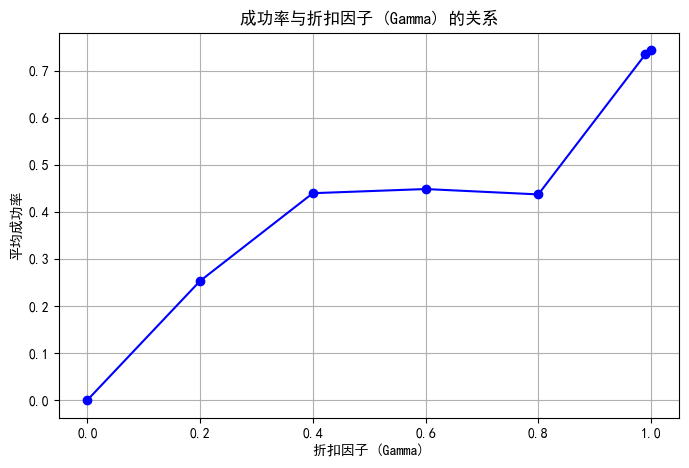

In [12]:
# ==========================================
# 3. 探究不同折扣因子 (gamma) 对成功率的影响
# ==========================================

print("\n" + "=" * 50)
print("【探究不同折扣因子 (gamma) 对成功率的影响】")
print("=" * 50)

gammas = [0, 0.2, 0.4, 0.6, 0.8, 0.99, 1.0]
n_episode = 10000  # 增加回合数以获得更平滑的曲线
avg_reward_gamma = []

for g in gammas:
    # 针对每个 gamma 重新计算最优策略
    V_opt = value_iteration(env, g, threshold)
    pol = extract_optimal_policy(env, V_opt, g)
    
    total_rewards = []
    for episode in range(n_episode):
        total_reward = run_episode(env, pol)
        total_rewards.append(total_reward)
        
    avg_reward_gamma.append(sum(total_rewards) / n_episode)
    print(f"  gamma = {g:.2f} -> 平均成功率: {avg_reward_gamma[-1]:.4f}")

# 绘制折线图（全中文配置）
plt.figure(figsize=(8, 5))
plt.plot(gammas, avg_reward_gamma, marker='o', linestyle='-', color='b')
plt.title('成功率与折扣因子 (Gamma) 的关系')
plt.xlabel('折扣因子 (Gamma)')
plt.ylabel('平均成功率')
plt.grid(True)
plt.show()

# 关闭环境释放资源
env.close()

这段代码是第二章的**压轴核心**，它实现了 **价值迭代（Value Iteration）** 算法。

之前跑的“随机搜索”是靠**碰运气**，那么这段代码就是靠**纯数学计算**。它利用了环境的底牌（转移概率矩阵 $P$），通过**贝尔曼最优方程（Bellman Optimality Equation）**反复“自举（Bootstrapping）”，直接推导出每个格子的绝对价值，从而计算出真正的**最优策略**。

### 💡 核心算法原理解析：
1. **价值迭代（Value Iteration）**：
   它不需要像策略迭代那样先“评估策略”再“改进策略”。它直接利用**贝尔曼最优方程**：$V(s) = \max_a \sum P(s'|s,a) \cdot [R + \gamma V(s')]$。
   
   简单来说，就是假设自己未来每一步都会做出最完美的选择（取 `max`），然后倒推当前状态到底值多少分。
2. **提取最优策略（Extract Policy）**：
   当所有格子的价值 $V(s)$ 都算准之后，智能体只需要站在当前格子，看看往哪个方向走能到达价值最高的格子，那个方向就是最优动作（贪心策略）。
3. **折扣因子（Gamma）的意义**：
   代码最后画了一张图。你会发现，当 $\gamma=0$ 时，智能体只看眼前，成功率极低；随着 $\gamma$ 趋近于 1，智能体开始“目光长远”，为了最终拿到终点那 1 分，愿意承担冰面滑动的风险，成功率会大幅提升。